In [1]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit import quantum_info as qi
from qiskit.visualization import array_to_latex, plot_bloch_multivector
from qiskit_aer import Aer

#### create a circuit consisting of a quantum register with 2 qubits and a classical register with two bits
#### add a $CX$ gate having the first qubit as control and the second qubit as target

In [2]:
qr = QuantumRegister(2, "qreg")
cr = ClassicalRegister(2, "creg")
qc = QuantumCircuit(qr, cr)
qc.cx(qr[0], qr[1])
qc.draw(initial_state=True)

qreg_0: |0>──■──
           ┌─┴─┐
qreg_1: |0>┤ X ├
           └───┘
 creg: 0 2/═════

In [3]:
op = qi.Operator.from_circuit(qc)
print(op)

Operator([[1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
          [0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j],
          [0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
          [0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))


In [4]:
array_to_latex(op)

<IPython.core.display.Latex object>

#### create again the circuit and add an $X$ gate on the first qubit before adding the $CX$

In [5]:
qr = QuantumRegister(2, "qreg")
cr = ClassicalRegister(2, "creg")
qc = QuantumCircuit(qr, cr)
qc.x(qr[0])
qc.cx(qr[0], qr[1])
qc.draw(initial_state=True)

┌───┐     
qreg_0: |0>┤ X ├──■──
           └───┘┌─┴─┐
qreg_1: |0>─────┤ X ├
                └───┘
 creg: 0 2/══════════

#### check using a state vector simulation that the second qubit changes from $\lvert 0 \rangle$ to $\lvert 1 \rangle$

In [6]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()

#### $[0~~0~~0~~1]$ corresponds to both qubits in $\lvert 1 \rangle$ state

In [7]:
array_to_latex(psi_f)

<IPython.core.display.Latex object>

#### check this by plotting the qubits on their Bloch spheres

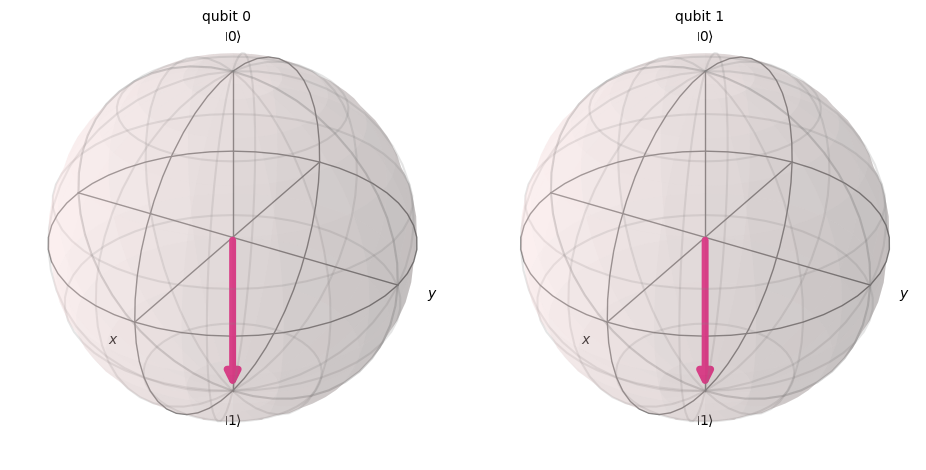

In [8]:
plot_bloch_multivector(psi_f)

#### generate a random unitary operator using a fixed random seed

In [9]:
U = qi.random_unitary(dims=2, seed=27112025)
print(U)

Operator([[ 0.31466829-0.81847629j,  0.47995498+0.02690073j],
          [ 0.22895206-0.42268356j, -0.86185723-0.16162205j]],
         input_dims=(2,), output_dims=(2,))


#### create an instruction (a gate) from this operator

In [10]:
UG = U.to_instruction()

In [11]:
UG

Instruction(name='unitary', num_qubits=1, num_clbits=0, params=[array([[ 0.31466829-0.81847629j,  0.47995498+0.02690073j],
       [ 0.22895206-0.42268356j, -0.86185723-0.16162205j]])])

#### create a one qubit circuit and add the gate corresponding to this operator

In [12]:
qr = QuantumRegister(1)
qc = QuantumCircuit(qr)
qc.append(UG,qr)
qc.draw()

┌─────────┐
q0: ┤ Unitary ├
    └─────────┘

#### use the "transpiler" to decompose this arbitrary unitary into rotations around the $x,z$ axes

In [13]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

backend = Aer.get_backend('qasm_simulator')
target = backend.target
pm = generate_preset_pass_manager(basis_gates=['rx', 'rz', 'cx'])
qc_t = pm.run(qc)

In [14]:
qc_t.draw()

global phase: 1.0616
    ┌────────────┐┌────────────┐┌────────────┐
q0: ┤ Rz(2.8305) ├┤ Rx(1.0029) ├┤ Rz(1.7002) ├
    └────────────┘└────────────┘└────────────┘

#### entanglement: a circuit to create a Bell pair of qubits

In [15]:
qr = QuantumRegister(2)
qc = QuantumCircuit(qr)
qc.h(qr[0])
qc.cx(qr[0], qr[1])
qc.draw(initial_state=True)

┌───┐     
q1_0: |0>┤ H ├──■──
         └───┘┌─┴─┐
q1_1: |0>─────┤ X ├
              └───┘

#### simulate the state vector

In [16]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()
array_to_latex(psi_f)

<IPython.core.display.Latex object>

#### the qubits are entangled, they can not be separated, their plot on the Bloch sphere looks strange...
#### the qubits are no more "sitting" on the surface of each Bloch sphere

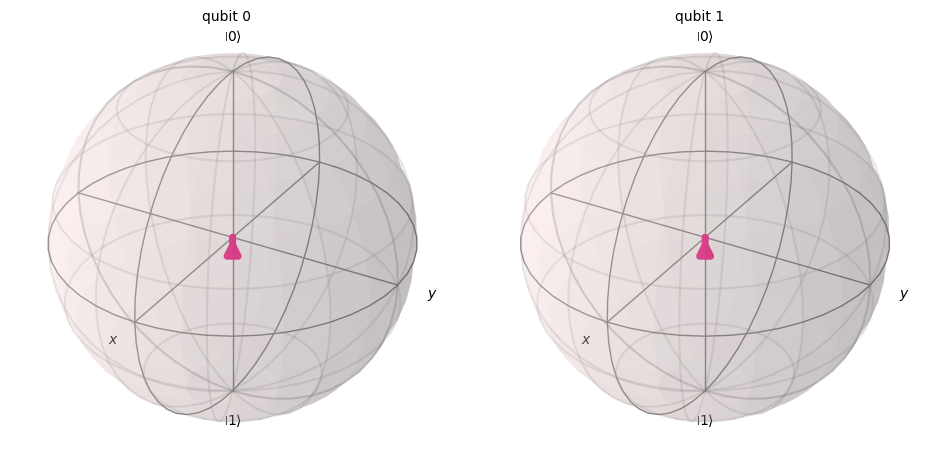

In [17]:
plot_bloch_multivector(psi_f)

#### extract the total density matrix

In [18]:
rho_f = qi.DensityMatrix(psi_f)
array_to_latex(rho_f)

<IPython.core.display.Latex object>

In [19]:
rho_f.is_valid()

True

#### do a partial trace on the density matrix in order to "ignore" one of the qubits (the first)

In [20]:
rho_f_q1 = qi.partial_trace(rho_f, [0])
array_to_latex(rho_f_q1)

<IPython.core.display.Latex object>

#### check the purity of the total system

In [21]:
print(rho_f.purity())

(1+0j)


#### check the purity of the second qubit (from the reduced matrix)

In [22]:
print(rho_f_q1.purity())

(0.5+0j)


#### $\Rightarrow$ this qubit (and the conclusion is the same for the other one) is in a mixed state, due to the entanglement

#### add measurements (in the computational basis)

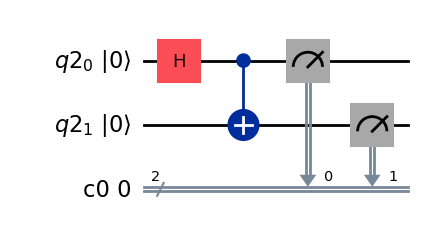

In [23]:
qr = QuantumRegister(2)
cr = ClassicalRegister(2)
qc = QuantumCircuit(qr, cr)
qc.h(qr[0])
qc.cx(qr[0], qr[1])
qc.measure(qr, cr)
qc.draw('mpl', initial_state=True)

#### use a backend called "qasm_simulator" and do 10000 execution of the above circuit; 
#### extract the results of the measurements

In [24]:
backend = Aer.get_backend('qasm_simulator')
job = backend.run(qc, shots=10000)
counts = job.result().get_counts(qc)

#### the 10000 measurements (shots) are summarized in a Python dictionary

In [25]:
print(counts)

{'11': 5011, '00': 4989}


#### print the results in a nice histogram

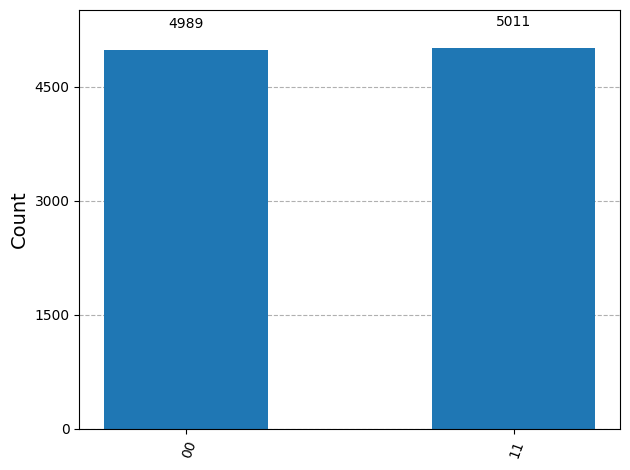

In [26]:
from qiskit.visualization import plot_histogram
plot_histogram(counts)

#### the above "qasm_simulator" is an ideal simulator, without any quantum noise
#### now use a simulator mimicking a real quantum processor, affected by errors

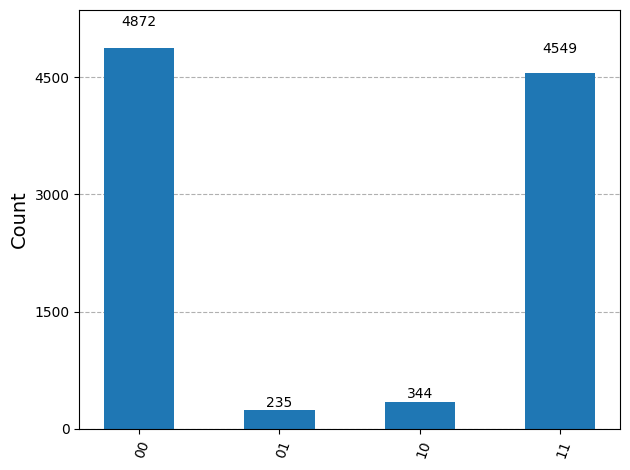

In [27]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
backend = FakeManilaV2()
job = backend.run(qc, shots=10000)
counts = job.result().get_counts(qc)
plot_histogram(counts)

#### create an empty quantum circuit which only measures the initial $\lvert 0 \rangle$ states of the two qubits

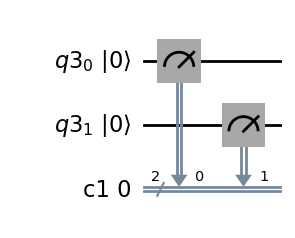

In [28]:
qr = QuantumRegister(2)
cr = ClassicalRegister(2)
qc = QuantumCircuit(qr, cr)
qc.measure(qr, cr)
qc.draw('mpl', initial_state=True)

#### do a larger number of measurements (shots): 100000

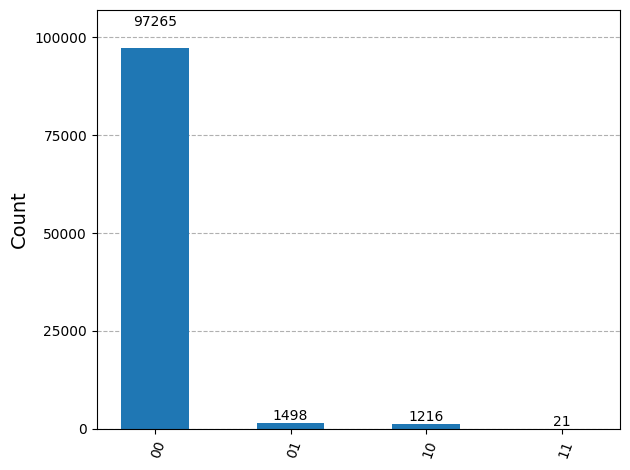

In [29]:
job = backend.run(qc, shots=100000)
counts = job.result().get_counts(qc)
plot_histogram(counts)

#### $\Rightarrow$ from here we see that there is a probability that a qubit flips spontaneously to the $\lvert 1 \rangle$ state

#### do the same exercice but on the $\lvert 1 \rangle$ states

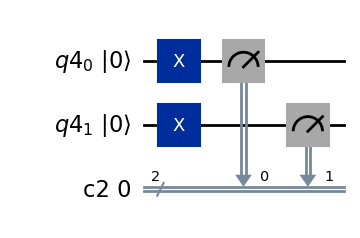

In [30]:
qr = QuantumRegister(2)
cr = ClassicalRegister(2)
qc = QuantumCircuit(qr, cr)
qc.x(qr)
qc.measure(qr, cr)
qc.draw('mpl', initial_state=True)

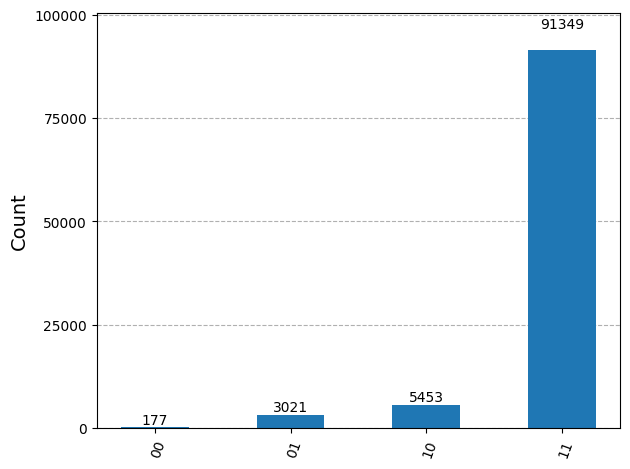

In [31]:
job = backend.run(qc, shots=100000)
counts = job.result().get_counts(qc)
plot_histogram(counts)

#### $\Rightarrow$ the "flipping" probabilities look larger than in the previous case;
#### this can come from the error in the functionning of the $X$ gate or from the higher instability 
#### of the $\lvert 1 \rangle$ state compared to the $\lvert 0 \rangle$ state

#### extra

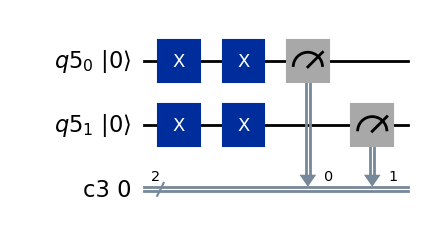

In [32]:
qr = QuantumRegister(2)
cr = ClassicalRegister(2)
qc = QuantumCircuit(qr, cr)
qc.x(qr)
qc.x(qr)
qc.measure(qr, cr)
qc.draw('mpl', initial_state=True)

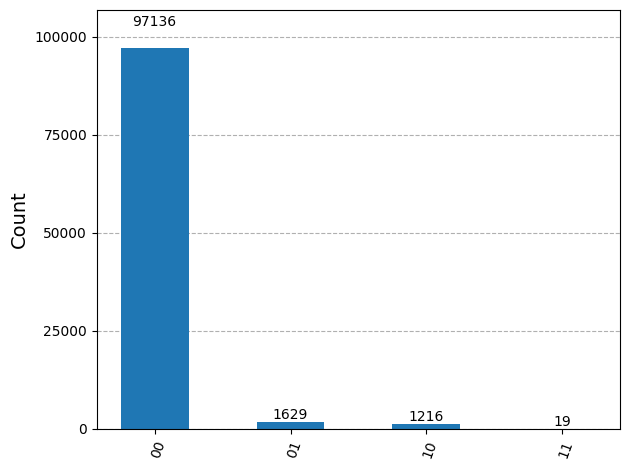

In [33]:
job = backend.run(qc, shots=100000)
counts = job.result().get_counts(qc)
plot_histogram(counts)